# Daily Challenge: Analysis of Airplane Crashes and Fatalities

**What you will create**
A thorough analysis of the “Airplane Crashes and Fatalities up to 2023” dataset, including detailed visualizations and statistical insights.


**Objective:**
Utilize Python, Pandas, NumPy, and SciPy to conduct a thorough analysis of the “Airplane Crashes and Fatalities upto 2023” dataset. This challenge will encompass data cleaning, exploratory analysis, statistical testing, and visualization to draw meaningful insights.



**Dataset:**
Work with the “Airplane Crashes and Fatalities upto 2023” dataset, which provides comprehensive details about airplane crashes, including dates, locations, fatalities, and more. Access the dataset here.

**Tasks**:

**1. Data Import and Cleaning:**

Import the dataset using Pandas.
Clean and preprocess the data, addressing missing values and categorizing data as needed.
Convert dates and other relevant fields to appropriate formats.

In [92]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [99]:
crashes = pd.read_csv('/content/Airplane_Crashes_and_Fatalities_Since_1908_t0_2023.csv')

,Date,Time,Location,Operator,Flight #,Route,AC Type,Registration,cn/ln,Aboard,Aboard Passangers,Aboard Crew,Fatalities,Fatalities Passangers,Fatalities Crew,Ground,Summary
0,9/17/1908,17:18,"Fort Myer, Virginia",Military - U.S. Army,NaN,Demonstration,Wright Flyer III,NaN,1,2.0,1.0,1.0,1.0,1.0,0.0,0.0,"During a demonstration flight, a U.S. Army fly..."
1,9/7/1909,NaN,"Juvisy-sur-Orge, France",NaN,NaN,Air show,Wright Byplane,SC1,NaN,1.0,0.0,1.0,1.0,0.0,0.0,0.0,Eugene Lefebvre was the first pilot to ever be...
2,7/12/1912,6:30,"Atlantic City, New Jersey",Military - U.S. Navy,NaN,Test flight,Dirigible,NaN,NaN,5.0,0.0,5.0,5.0,0.0,5.0,0.0,First U.S. dirigible Akron exploded just offsh...
3,8/6/1913,NaN,"Victoria, British Columbia, Canada",Private,NaN,NaN,Curtiss seaplane,NaN,NaN,1.0,0.0,1.0,1.0,0.0,1.0,0.0,The first fatal airplane accident in Canada oc...
4,9/9/1913,18:30,Over the North Sea,Military - German Navy,NaN,NaN,Zeppelin L-1 (airship),NaN,NaN,20.0,NaN,NaN,14.0,NaN,NaN,0.0,The airship flew into a thunderstorm and encou...


In [100]:
# Reviewing the data, data availability, NaNs:
crashes.info()
crashes.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4998 entries, 0 to 4997
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Date                   4998 non-null   object 
 1   Time                   3486 non-null   object 
 2   Location               4994 non-null   object 
 3   Operator               4988 non-null   object 
 4   Flight #               1329 non-null   object 
 5   Route                  4221 non-null   object 
 6   AC Type                4983 non-null   object 
 7   Registration           4724 non-null   object 
 8   cn/ln                  4330 non-null   object 
 9   Aboard                 4980 non-null   float64
 10  Aboard Passangers      4769 non-null   float64
 11  Aboard Crew            4772 non-null   float64
 12  Fatalities             4990 non-null   float64
 13  Fatalities Passangers  4756 non-null   float64
 14  Fatalities Crew        4757 non-null   float64
 15  Grou

,0
Date,0
Time,1512
Location,4
Operator,10
Flight #,3669
Route,777
AC Type,15
Registration,274
cn/ln,668
Aboard,18


In [101]:
# converting date to a numeric column:
crashes['Date'] = pd.to_datetime(crashes['Date'])
print(crashes['Date'][0:5])

# converting time column also into a numeric one (taking only the hour)
crashes['Time'] = crashes['Time'].apply(lambda x: int(str(x).split(":")[0]) if str(x).upper() != "NAN" else np.nan)
print(crashes['Time'][0:5])


0   1908-09-17
1   1909-09-07
2   1912-07-12
3   1913-08-06
4   1913-09-09
Name: Date, dtype: datetime64[ns]
0    17.0
1     NaN
2     6.0
3     NaN
4    18.0
Name: Time, dtype: float64


In [96]:
crashes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4998 entries, 0 to 4997
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Date                   4998 non-null   datetime64[ns]
 1   Time                   3486 non-null   float64       
 2   Location               4994 non-null   object        
 3   Operator               4988 non-null   object        
 4   Flight #               1329 non-null   object        
 5   Route                  4221 non-null   object        
 6   AC Type                4983 non-null   object        
 7   Registration           4724 non-null   object        
 8   cn/ln                  4330 non-null   object        
 9   Aboard                 4980 non-null   float64       
 10  Aboard Passangers      4769 non-null   float64       
 11  Aboard Crew            4772 non-null   float64       
 12  Fatalities             4990 non-null   float64       
 13  Fat

In [102]:
# drop not needed for analysis columns, especially the ones with many missing values:
crashes.drop(columns=['Flight #','Registration'],inplace=True)

In [103]:
print(f"cn/ln unique values: {crashes['cn/ln'].value_counts()} \n")
# cn/ln has too many unique non-numeric values -> drop
crashes.drop(columns=['cn/ln'],inplace=True)

In [104]:
# time is missing the most values from the remaining columns, where we can replace the NaN with the average hour value:
crashes['Time']=crashes['Time'].fillna(int(crashes['Time'].mean()))
crashes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4998 entries, 0 to 4997
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Date                   4998 non-null   datetime64[ns]
 1   Time                   4998 non-null   float64       
 2   Location               4994 non-null   object        
 3   Operator               4988 non-null   object        
 4   Route                  4221 non-null   object        
 5   AC Type                4983 non-null   object        
 6   Aboard                 4980 non-null   float64       
 7   Aboard Passangers      4769 non-null   float64       
 8   Aboard Crew            4772 non-null   float64       
 9   Fatalities             4990 non-null   float64       
 10  Fatalities Passangers  4756 non-null   float64       
 11  Fatalities Crew        4757 non-null   float64       
 12  Ground                 4956 non-null   float64       
 13  Sum

In [145]:
# time might be interesting to analyze so we better keep it and drop the remaining NaNs:
crashes.dropna(inplace=True)
crashes.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4103 entries, 0 to 4997
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Date                     4103 non-null   datetime64[ns]
 1   Time                     4103 non-null   float64       
 2   Location                 4103 non-null   object        
 3   Route                    4103 non-null   object        
 4   AC Type                  4103 non-null   float64       
 5   Aboard                   4103 non-null   float64       
 6   Aboard Passangers        4103 non-null   float64       
 7   Aboard Crew              4103 non-null   float64       
 8   Fatalities               4103 non-null   float64       
 9   Fatalities Passangers    4103 non-null   float64       
 10  Fatalities Crew          4103 non-null   float64       
 11  Ground                   4103 non-null   float64       
 12  Summary                  4103 non-null 

In [106]:
# We kept about 80% of the data after the clean-up.
# Now we shuold try encode some of the remaining non-numeric values. First we need to see how many unique values those have:
print(f"Location unique values: {crashes['Location'].value_counts()} \n")
print(f"Operator unique values: {crashes['Operator'].value_counts()} \n")
print(f"Route unique values: {crashes['Route'].value_counts()} \n")
print(f"AC Type unique values: {crashes['AC Type'].value_counts()} \n")


Location unique values: Location
Moscow, Russia            16
Manila, Philippines       14
New York, New York        13
Rio de Janeiro, Brazil    11
Sao Paulo, Brazil         11
                          ..
 Morelos,  Mexico          1
Fort Myer, Virginia        1
Mt. Nittany, Ohio          1
Rosas, Spain               1
Landrécies, France         1
Name: count, Length: 3419, dtype: int64 

Operator unique values: Operator
Aeroflot                     233
Military - U.S. Air Force    107
Air France                    57
United Air Lines              42
Deutsche Lufthansa            41
                            ... 
Inex Adria Aviopromet          1
Connair                        1
Wien Air Alaska                1
Aerovias Condor                1
Inair Panama                   1
Name: count, Length: 1977, dtype: int64 

Route unique values: Route
Training                      87
Sightseeing                   31
Test flight                   22
Sao Paulo - Rio de Janeiro     7
Rio de Ja

Conclusions after inspecting unique non-numeric values:
*    Location -> reduce to country via splitting by ' ,' and take last element - DONE below, but even turning states to United States still 400 values, too many -> next steps: >10 + Other -> target-encode by average number of fatalities

*    Route -> encode into Training true/false, Sightseeing, contains Test

*    Operator -> many uniques, but can encode military - DONE below

*    AC Type - encode first word of the name -> still too many -> next target-encode by average number of fatalities  - DONE below

In [108]:
# Location -> reduce to country via splitting by ', ' and take last element
crashes['Location'] = crashes['Location'].apply(lambda x: x.split(', ')[-1])
crashes['Location'].value_counts()

In [109]:
pip install us

In [110]:
# now importing state names in the U.S. and mapping states to United States
import us
us_states_lst = us.states.STATES_AND_TERRITORIES
us_states_lst = [str(l) for l in us_states_lst]
# mapping states to United States
crashes.loc[crashes['Location'].isin(us_states_lst),'Location'] = 'United States'

In [112]:
# Next, since still ca. 420 unique locations, we target-encode by avg fatalities if above 10 crashes, but we keep original col:
crashes['location_fatalities_avg'] = crashes.groupby('Location')['Fatalities'].transform(lambda x: x.mean() if x.count() > 10 else crashes['Fatalities'].mean())

In [113]:
# encode military:
crashes.loc[crashes['Operator'].str.contains('army|military|navy', case=False), 'Operator'] = 'military'
# now add the column 1 if military, 0 else:
crashes['military'] = crashes['Operator'].apply(lambda x: 1 if x == 'military' else 0)
# and target encode the original by Operator with >=10 counts with average fatalities within group:
crashes['operator_avg_fatalities'] = crashes.groupby('Operator')['Fatalities'].transform(lambda x: x.mean() if x.count() >= 10 else crashes['Fatalities'].mean())
# and drop the original Operator
# crashes.drop(columns=['Operator'],inplace=True)

KeyError: 'Operator'

In [84]:
# AC Type - encode first word of the name
crashes['AC Type'] = crashes['AC Type'].apply(lambda x: x.split(' ')[0])
crashes['AC Type'].value_counts()

,count
AC Type,
Douglas,746
Boeing,346
Lockheed,249
Antonov,212
de,211
...,...
\tEurocopter,1
ATR-42-500,1
Socata,1


In [114]:
# take all countries with more that 10 crashes, target encode and rest by respective averages
crashes['AC Type'] = crashes.groupby('AC Type')['Fatalities'].transform(lambda x: x.mean() if x.count() > 10 else crashes['Fatalities'].mean())

In [118]:
# Route -> encode into Training true/false, Sightseeing, contains Test
crashes['Training'] = crashes['Route'].apply(lambda x: 1 if 'training' in x.lower() else 0)
crashes['Sightseeing'] = crashes['Route'].apply(lambda x: 1 if 'sightseeing' in x.lower() else 0)
crashes['Test'] = crashes['Route'].apply(lambda x: 1 if 'test' in x.lower() else 0)
crashes['Demonstration'] = crashes['Route'].apply(lambda x: 1 if 'demonstration' in x.lower() else 0)

In [119]:
crashes.head(3)

,Date,Time,Location,Route,AC Type,Aboard,Aboard Passangers,Aboard Crew,Fatalities,Fatalities Passangers,Fatalities Crew,Ground,Summary,military,operator_avg_fatalities,location_fatalities_avg,Training,Sightseeing,Test,Demonstration
0,1908-09-17,17.0,United States,Demonstration,24.564677,2.0,1.0,1.0,1.0,1.0,0.0,0.0,"During a demonstration flight, a U.S. Army fly...",1,28.536998,16.105937,0,0,0,1
2,1912-07-12,6.0,United States,Test flight,24.564677,5.0,0.0,5.0,5.0,0.0,5.0,0.0,First U.S. dirigible Akron exploded just offsh...,1,28.536998,16.105937,0,0,1,0
27,1919-08-02,12.0,Italy,Venice Taliedo,24.564677,14.0,12.0,2.0,14.0,12.0,2.0,0.0,As the plane was passing over Verona the wings...,0,24.564677,22.389610,0,0,0,0


**2. Exploratory Data Analysis:**

Use Pandas to explore basic statistics such as the number of crashes, fatalities, and survival rates.
Analyze the frequency of crashes over time to identify any trends.

**3. Statistical Analysis:**

Apply SciPy to analyze the distribution of fatalities and survival rates. Calculate key statistics like mean, median, and standard deviation.
Conduct a hypothesis test (e.g., comparing the average number of fatalities in different decades or regions).

**4. Visualization:**

Create charts and graphs using Matplotlib and Seaborn to visualize the findings from your exploratory data analysis and statistical tests.
Examples might include time series plots of crashes over years, bar charts of crashes by region, and histograms of fatalities.

**5. Insight and Report:**

Summarize your findings and provide insights into the patterns or anomalies discovered in the data.
Prepare a well-structured report including all code, visualizations, and interpretations.


**Submission:**
You should submit a comprehensive report encompassing their code, analysis, and visualizations. Articulate how you have applied NumPy, Pandas, and SciPy in your analysis, highlighting any significant patterns or insights discovered in the dataset.

In [132]:
# ── 2. EDA ──────────────────────────────────────────────
crashes['year'] = crashes['Date'].dt.year
crashes['survival_rate'] = 1-crashes['Fatalities']/crashes['Aboard']
print(crashes[['Fatalities','Aboard','survival_rate']].describe())

        Fatalities       Aboard  survival_rate
count  4105.000000  4105.000000    4103.000000
mean     24.564677    34.293544       0.183364
std      37.702452    48.609479       0.313639
min       0.000000     0.000000       0.000000
25%       4.000000     7.000000       0.000000
50%      12.000000    18.000000       0.000000
75%      28.000000    39.000000       0.250000
max     583.000000   644.000000       1.000000


<Axes: title={'center': 'Crashes/Year'}, xlabel='year'>

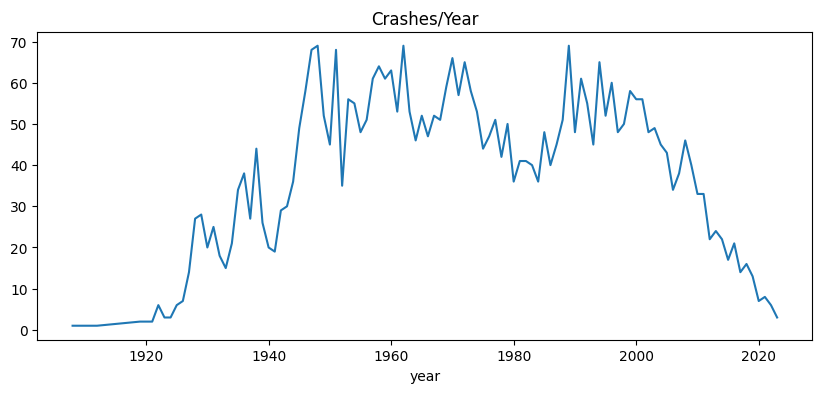

In [134]:
crashes_per_year = crashes.groupby('year').size()
crashes['year'].value_counts().sort_index().plot(figsize=(10,4), title="Crashes/Year")


In [146]:
print(f"average fatalities: {stats.tmean(crashes['Fatalities'])}")
print(f"median fatalities: {np.median(crashes['Fatalities'])}")
print(f"standard dev of # of fatalities: {stats.tstd(crashes['Fatalities'])}")

# and same for survival rates:
print(f"average survival rate: {stats.tmean(crashes['survival_rate'])}")
print(f"median survival rate: {np.median(crashes['survival_rate'])}")
print(f"standard dev of survival rate: {stats.tstd(crashes['survival_rate'])}")


average fatalities: 24.57665123080673
median fatalities: 12.0
standard dev of # of fatalities: 37.707739698258386
average survival rate: 0.18336394466207948
median survival rate: 0.0
standard dev of survival rate: 0.3136389704746899


In [164]:
# ── 3. Statistical Analysis ─────────────────────────────
# decades:
crashes['decade'] = ((crashes['year']) // 10) * 10
# grouping fatalities by decade
decade_crashes = [g['Fatalities'].values for _, g in crashes.groupby('decade') if len(g) > 10]
f_stat, p_val = stats.f_oneway(*decades)          # ANOVA across decades
print(f"F={f_stat:.2f}, p={p_val:.4f}")

F=21.32, p=0.0000


--> p value basically 0, means average fatalities per decade are singificantly different from each other

In [165]:
# Fatality distribution
print(f"Skew: {stats.skew(crashes['Fatalities']):.2f}, Kurtosis: {stats.kurtosis(crashes['Fatalities']):.2f}")
print(f"Skew: {stats.skew(crashes['survival_rate']):.2f}, Kurtosis: {stats.kurtosis(crashes['survival_rate']):.2f}")

Skew: 4.32, Kurtosis: 31.92
Skew: 1.53, Kurtosis: 0.84


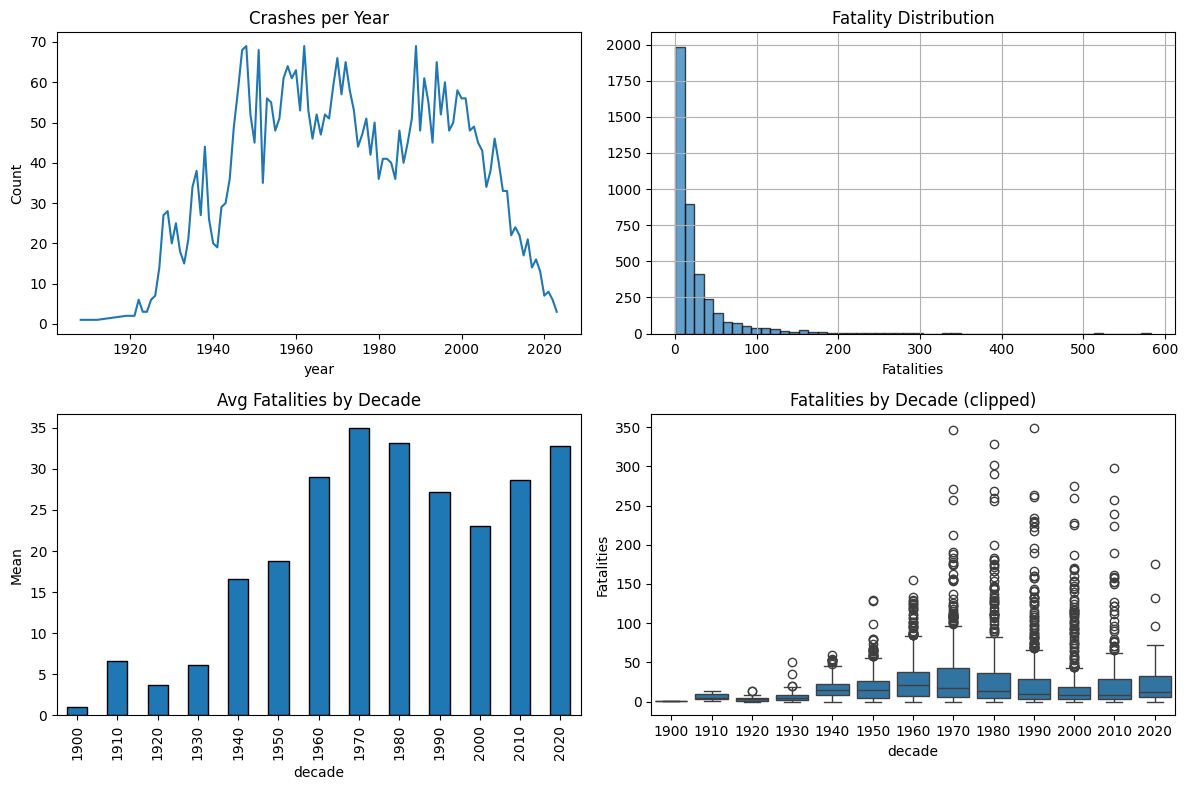

In [166]:
# ── 4. Visualization ────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

crashes_per_year.plot(ax=axes[0,0], title="Crashes per Year")
axes[0,0].set_ylabel("Count")

crashes['Fatalities'].hist(bins=50, ax=axes[0,1], edgecolor='k', alpha=0.7)
axes[0,1].set(title="Fatality Distribution", xlabel="Fatalities")

crashes.groupby('decade')['Fatalities'].mean().plot(kind='bar', ax=axes[1,0], edgecolor='k')
axes[1,0].set(title="Avg Fatalities by Decade", ylabel="Mean")

sns.boxplot(data=crashes[crashes['Fatalities']<500], x='decade', y='Fatalities', ax=axes[1,1])
axes[1,1].set(title="Fatalities by Decade (clipped)")

plt.tight_layout()
plt.show()

In [168]:
# ── 5. Insight / Report ─────────────────────────────────
print(f"""
SUMMARY
-------
• Total crashes: {len(crashes):,} | Total fatalities: {crashes['Fatalities'].sum():,}
• Peak decade (crashes): {crashes_per_year.idxmax()} ({crashes_per_year.max()} crashes)
• ANOVA across decades: {'significant' if p_val < 0.05 else 'not significant'} (p={p_val:.4f})
• Fatality distribution: highly right-skewed (median={crashes['Fatalities'].median()}, mean={crashes['Fatalities'].mean():.1f})
• Most crashes occur in hour: {crashes['Time'].mode()[0] if crashes['Time'].notna().any() else 'N/A'}
""")


SUMMARY
-------
• Total crashes: 4,103 | Total fatalities: 100,838.0
• Peak decade (crashes): 1948 (69 crashes)
• ANOVA across decades: significant (p=0.0000)
• Fatality distribution: highly right-skewed (median=12.0, mean=24.6)
• Most crashes occur in hour: 12.0

